<h1>Практическая работа: "Бинарная логистическая регрессия"</h1>

__Задача бинарной классификации__

___Некая фирма провела анализ зависимости расхода денежных средств на рекламу и эффекта от нее. Если эффект присутствовал, 
то в датасете ставилась 1, в противном случае - 0. Результаты были представоены в виде двух DataFrame х и y.<br>
Произыести бинарную классификацию с использованием логистической регрессии.___  

In [1]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
#display(x, Y)

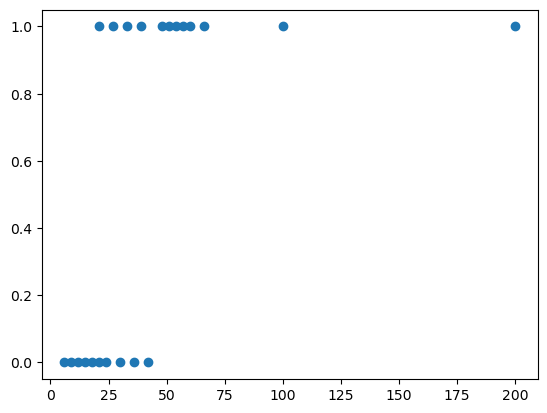

In [4]:
plt.scatter(x,Y)

_Попробуем разделить эти точки прямой линией, отделяющей один класс от другого. 
Модель начинает плохо работать в случае добавления новых точек на больших значениях x:_

In [5]:
a1 = ((x-x.mean())*(Y-Y.mean())).mean()/((x-x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Y = ", a0, " + ", a1, " * x")
x_space = np.linspace(6,70,20)
Y_pred = a0.item() + a1.item()*x_space

Y =  0    0.266493
dtype: float64  +  0    0.006333
dtype: float64  * x


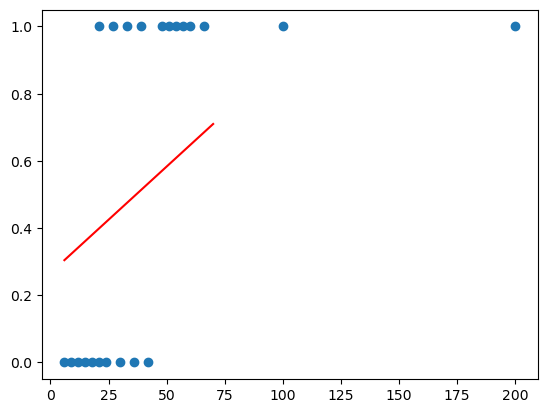

In [6]:
plt.plot(x_space, Y_pred, 'r')
plt.scatter(x, Y)

<h2>Функция логистической регрессии</h2>

__Сигмоида__

Возможное решение упомянутых выше сложностей — пропустить значение линейной регрессии через сигмоиду (sigmoid function), 
которая при любом значении x не выйдет из необходимого нам диапазона от 0 до 1. <br>
<h3>$g(x) = \frac{1}{1+ e^{-x}}$</h3>

 <img src='images/ris1.png' width=320, heigth=240>

<h3>Logistic loss или функция кросс-энтропии</h3>

В модели логистической регрессии мы не можем использовать MSE. Дело в том, 
что если мы поместим результат сигмоиды (представляющей собою нелинейную функцию) в MSE, 
то на выходе получим невыпуклую функцию (non-convex), глобальный минимум которой довольно сложно найти.
 <img src='images/ris2.png' width=520, heigth=240>
    Вместо MSE мы будем использовать функцию логистической ошибки, которую еще называют функцией бинарной кросс-энтропии (log loss, binary cross-entropy loss).

__График и формула функции логистической ошибки__<br>
 <img src='images/ris3.png' width=420, heigth=240>

$J(\theta)=-\frac{1}{n} \sum{y*log(h_{\theta}(x))+(1-y)*log(1-h_{\theta}(x))}$

<h3>Оценка качества модели</h3>

__Матрицa ошибок (confusion matrix)__<br>
 <img src='images/ris4.png' width=420, heigth=240><br>
Доля правильно предсказанных значений называется accuracy. Чтобы ее посчитать, мы берем те значения,
    которые предсказаны верно (TP + TN) и делим на общее количество прогнозов.<br>
    <h3>$accuracy=\frac{TP+TN}{TP+TN+FP+FN}$</h3>

<h2>Конкретизация задачи:</h2>

Реализовать класс модели логистической регрессии с использованием:

а) максимизации логарифмического правдоподобия методом градиентного подъема

б) минимизации функции потерь (кросс-энтропии) методом градиентного спуска

Сравнить результаты (время исполнения и достигнутые значения accuracy и f1) в случаях а и б при одном и том же числе шагов и скорости обучения.

In [7]:
#Реализуем цикл градиентного спуска
class LogisticRegressionGD(object):
    def __init__(self):
        self.a = np.zeros(2).reshape(1, 2)
        
    def sigmoid(self, x):
        return 1/(1 + np.exp(-x @ self.a))
    
    def predict(self, x):
        return self.sigmoid(x)
    
    def coefs(self):
        return self.a
      
    def LogLikelihood(self, x, Y):
        return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()

    def CrossEntropy(self, x, Y):
        return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()
    
    def accuracy(self, x, Y):
        return ((self.predict(x) > 0.5)==Y).mean() 

    def fit(self, x, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL"):
        self.a = np.zeros (x.shape[1]).reshape(x.shape[1],1)
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            if Rtype == "LL":
                new_error = self.LogLikelihood(x, Y)
                dT_a = x.T @(Y - self.predict(x)) / x.shape[0]
                self.a += alpha*dT_a
            elif Rtype == "CE":
                new_error = self.CrossEntropy(x, Y)
                #display(new_error)
                dT_a = -x.T @(Y - self.predict(x)) / x.shape[0]
                self.a -= alpha*dT_a
            step += 1
            steps.append(step)
            errors.append(new_error)
            #if new_error < epsylon:
            #    break
        return steps, errors

In [8]:
x_ = x.copy()

import time

intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis = 1))

In [117]:
start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE =  regr_CE.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "CE") 

display(f"Время обучения: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL =  regr_LL.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL") 

display(f"Время обучения: {time.time() - start_time_LL} сек.")

'Время обучения: 51.10913443565369 сек.'

'Время обучения: 54.79919672012329 сек.'

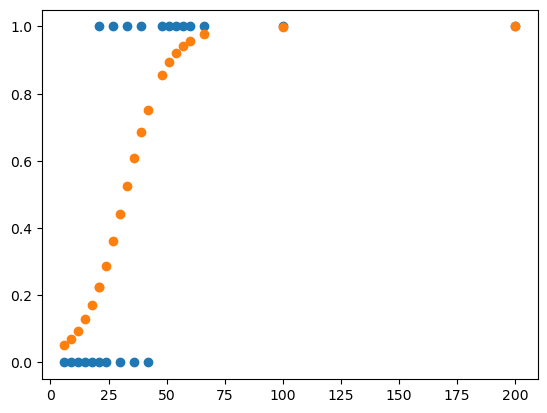

In [118]:
Y_Pred = regr_CE.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [126]:
display(regr_CE.coefs())
#display(x_)

,0
0,-3.598810
1,0.112152


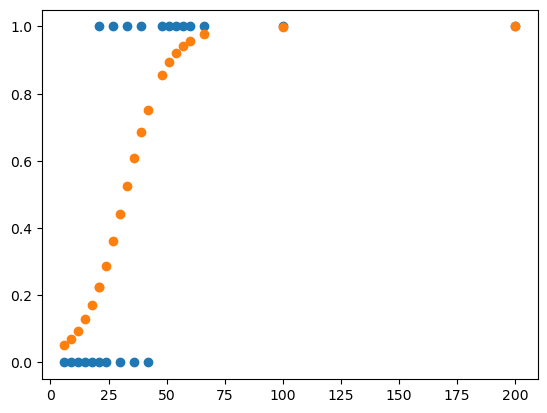

In [120]:
Y_Pred = regr_LL.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [125]:
display(regr_LL.coefs())
#display(x_)

,0
0,-3.598810
1,0.112152


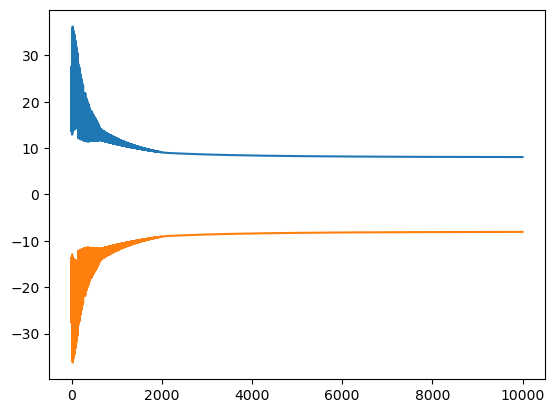

In [122]:
plt.plot(steps_CE, errors_CE)
plt.plot(steps_LL, errors_LL)

In [123]:
print(regr_CE.accuracy(x_, Y))
print(regr_LL.accuracy(x_, Y))

0    0.818182
dtype: float64
0    0.818182
dtype: float64


Реализовать расчеты способами а и б для набора данных из файла insclass_train.csv/
Для 151 406 договоров страхования транспортных средств известны значения ряда признаков, в том числе пол, возраст, стаж вождения и коэффициент бонус-малус водителя, тип, марка, модель, год выпуска, страна – производитель, мощность и объем двигателя, а также признак target, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае (файл insclass_train.csv).

Требуется построить модель, предсказывающую значение признака target для 22 624 договоров из тестового набора данных (файл insclass_test.csv).

В обучающем наборе данных для каждого договора известны следующие поля:

variable_1 - агрегированный коэффициент бонус-малус (повышающий или понижающий стоимость полиса в зависимости от аварийности в предыдущие периоды);
variable_2 - индикатор расторжения договора по инициативе страхователя (клиента);
variable_3 - индикатор расторжения договора по инициативе страховщика (страховой компании);
variable_4 - идентификатор года выпуска транспортного средства;
variable_5 - идентификатор страны - производителя транспортного средства;
variable_6 - мощность двигателя в лошадиных силах;
variable_7 - объем двигателя в куб. см;
variable_8 - идентификатор стороны расположения руля (левый или правый);
variable_9 - пробег транспортного средства, покрываемый гарантией производителя;
variable_10 - индикатор действия гарантии на транспортное средство;
variable_11 - "мультидрайв" - индикатор допуска к управлению транспортным средством более одного водителя;
variable_12 - возраст транспортного средства (в мес.);
variable_13 - возраст водителя с максимальным стажем;
variable_14 - коэффициент возраст-стаж;
variable_15 - коэффициент краткосрочности;
variable_16 - коэффициент мощности;
variable_17 - коэффициент "мультидрайв";
variable_18 - территориальный коэффициент;
variable_19 - коэффициент "КНДР";
variable_20 - идентификатор канала продаж;
variable_21 - марка транспортного средства;
variable_22 - модель транспортного средства;
variable_23 - индикатор отечественных транспортных средств;
variable_24 - пол водителя с максимальным коэффициентом "возраст-стаж";
variable_25 - индикатор пролонгации;
variable_26 - индикатор совпадения собственника транспортного средства и водителя;
variable_27 - стаж водителя с максимальным коэффициентом "возраст-стаж";
variable_28 - тип транспортного средства;
target - класс риска, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае.

In [6]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cat_cols = ['variable_1', 'variable_5', 'variable_20', 'variable_21', 'variable_22', 'variable_28']
bin_cols = ['variable_2', 'variable_8', 'variable_10', 'variable_11', 'variable_23', 'variable_24', 'variable_25', 'variable_26']
num_cols = ['variable_4', 'variable_6', 'variable_7', 'variable_9', 'variable_12', 'variable_13',
            'variable_14', 'variable_15', 'variable_16', 'variable_17', 'variable_18', 'variable_19', 'variable_27']

RULES = {'variable_6': (20, np.inf), 'variable_7': (100, np.inf), 'variable_9': (0, 300000)}
TOP_K = 15


def preprocess(df, params=None):
    fit = params is None
    if fit:
        params = {'top': {}, 'miss': {}, 'mean': {}, 'std': {}, 'bounds': {}}
    cols, names = [], []
    for c in cat_cols:
        s = df[c]
        if fit:
            params['top'][c] = list(s.value_counts().head(TOP_K).index)
            params['miss'][c] = bool(s.isna().any())
        for k in params['top'][c]:
            cols.append((s == k).astype(float).values)
            names.append(f'{c}={k}')
        cols.append((s.notna() & ~s.isin(params['top'][c])).astype(float).values)
        names.append(f'{c}=other')
        if params['miss'][c]:
            cols.append(s.isna().astype(float).values)
            names.append(f'{c}_na')
    for c in bin_cols:
        s = df[c].astype(float)
        if fit:
            params['miss'][c] = bool(s.isna().any())
            params['mean'][c] = s.mean()
        if params['miss'][c]:
            cols.append(s.isna().astype(float).values)
            names.append(f'{c}_na')
        cols.append(s.fillna(params['mean'][c]).values)
        names.append(c)
    for c in num_cols:
        lo, hi = RULES.get(c, (0, np.inf))
        s = df[c].astype(float).where(lambda v: (v >= lo) & (v <= hi))
        if fit:
            q = s.quantile([0.001, 0.999])
            params['bounds'][c] = (q.iloc[0], q.iloc[1])
        s = s.where((s >= params['bounds'][c][0]) & (s <= params['bounds'][c][1]))
        if fit:
            params['miss'][c] = bool(s.isna().any())
            params['mean'][c] = s.mean()
            params['std'][c] = s.std()
        if params['miss'][c]:
            cols.append(s.isna().astype(float).values)
            names.append(f'{c}_na')
        s = s.fillna(params['mean'][c])
        cols.append(((s - params['mean'][c]) / params['std'][c]).values)
        names.append(c)
    cols.insert(0, np.ones(len(df)))
    names.insert(0, 'intercept')
    return np.column_stack(cols).astype(np.float32), names, params


class LogisticRegression:
    def __init__(self, lr=0.01, n_steps=1000, mode='CE'):
        assert mode in ('CE', 'LL')
        self.lr, self.n_steps, self.mode = lr, n_steps, mode
        self.w, self.loss_history = None, []

    def _sigmoid(self, z):
        z = np.clip(z, -30, 30)
        return 1.0 / (1.0 + np.exp(-z))

    def _prob(self, X):
        return self._sigmoid(X @ self.w)

    def _cross_entropy(self, y, p):
        p = np.clip(p, 1e-7, 1 - 1e-7)
        return float(np.mean(-y * np.log(p) - (1 - y) * np.log(1 - p)))

    def _log_likelihood(self, y, p):
        p = np.clip(p, 1e-7, 1 - 1e-7)
        return float(np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

    def fit(self, X, y):
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
        n, m = X.shape
        self.w = np.zeros((m, 1), dtype=X.dtype)
        self.loss_history = []
        loss_fn = self._cross_entropy if self.mode == 'CE' else self._log_likelihood
        for _ in range(self.n_steps):
            p = self._prob(X)
            self.loss_history.append(loss_fn(y, p))
            
            if self.mode == 'CE':
                grad = X.T @ (p - y) / n
                self.w -= self.lr * grad
            else:
                grad = X.T @ (y - p) / n
                self.w += self.lr * grad
                
        return self

    def predict_proba(self, X):
        return self._prob(X)

    def predict(self, X, threshold=0.5):
        return (self._prob(X) > threshold).astype(int)


def accuracy(y, y_pred):
    return float((y.ravel() == y_pred.ravel()).mean())


def f1_score(y, y_pred):
    y, p = y.ravel(), y_pred.ravel()
    tp = int(((y == 1) & (p == 1)).sum())
    fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum())
    if tp == 0:
        return 0.0
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    return float(2 * prec * rec / (prec + rec))

In [7]:
train_df = pd.read_csv('insclass_train.csv')

rng = np.random.RandomState(42)
idx = rng.permutation(len(train_df))
n_test = int(0.2 * len(train_df))
test_part = train_df.iloc[idx[:n_test]].reset_index(drop=True)
train_part = train_df.iloc[idx[n_test:]].reset_index(drop=True)

X_train, names, params = preprocess(train_part)
X_test, _, _ = preprocess(test_part, params)
y_train = train_part['target'].values.reshape(-1, 1)
y_test = test_part['target'].values.reshape(-1, 1)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (121125, 112)
y_train: (121125, 1)
X_test: (30281, 112)
y_test: (30281, 1)


In [8]:
from sklearn.metrics import precision_score, recall_score

results, models = [], {}

for mode in ['CE', 'LL']:
    model = LogisticRegression(lr=0.01, n_steps=1000, mode=mode)
    
    t0 = time.time()
    model.fit(X_train, y_train)
    dt = time.time() - t0
    
    y_pred = model.predict(X_test)
    models[mode] = model
    
    results.append({
        'mode': 'а) Градиентный спуск (CE)' if mode == 'CE' else 'б) Градиентный подъём (LL)',
        'time_sec': round(dt, 3),
        'accuracy': round(accuracy(y_test, y_pred), 4),
        'precision_1': round(precision_score(y_test, y_pred, zero_division=0), 4),
        'recall_1': round(recall_score(y_test, y_pred, zero_division=0), 4),
        'f1_1': round(f1_score(y_test, y_pred), 4),
        'final_CE': round(model.loss_history[-1], 4) if mode == 'CE' else None,
        'final_LL': round(model.loss_history[-1], 4) if mode == 'LL' else None,
    })

display(pd.DataFrame(results))

,mode,time_sec,accuracy,precision_1,recall_1,f1_1,final_CE,final_LL
0,а) Градиентный спуск (CE),4.412,0.9086,0.733,0.088,0.1571,0.2929,NaN
1,б) Градиентный подъём (LL),4.987,0.9086,0.733,0.088,0.1571,NaN,-0.2929


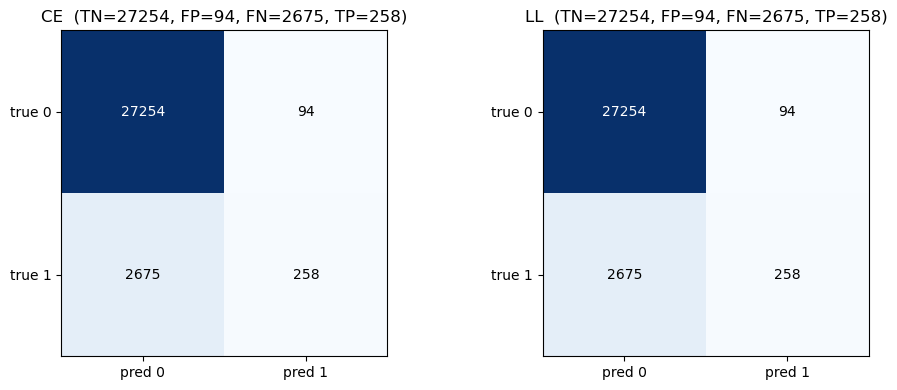

In [10]:
def confusion_matrix_manual(y, y_pred):
    y, p = y.ravel(), y_pred.ravel()
    tn = int(((y == 0) & (p == 0)).sum())
    fp = int(((y == 0) & (p == 1)).sum())
    fn = int(((y == 1) & (p == 0)).sum())
    tp = int(((y == 1) & (p == 1)).sum())
    return np.array([[tn, fp], [fn, tp]])


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, mode in zip(axes, ['CE', 'LL']):
    cm = confusion_matrix_manual(y_test, models[mode].predict(X_test))
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['pred 0', 'pred 1'])
    ax.set_yticklabels(['true 0', 'true 1'])
    ax.set_title(f'{mode}  (TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]})')
plt.tight_layout()
plt.show()

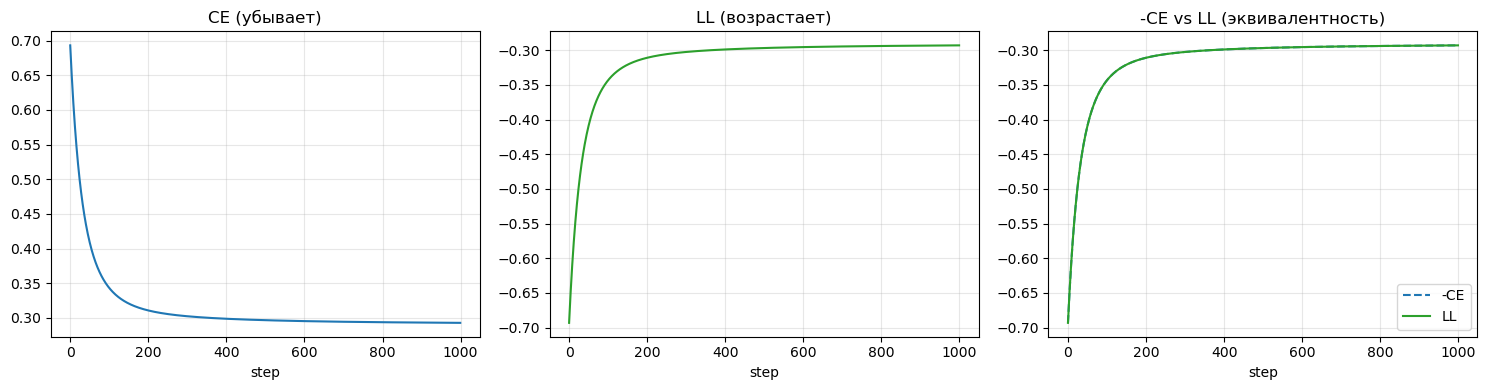

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(models['CE'].loss_history, color='tab:blue')
axes[0].set_title('CE (убывает)')
axes[0].set_xlabel('step'); axes[0].grid(alpha=.3)

axes[1].plot(models['LL'].loss_history, color='tab:green')
axes[1].set_title('LL (возрастает)')
axes[1].set_xlabel('step'); axes[1].grid(alpha=.3)

axes[2].plot([-e for e in models['CE'].loss_history], label='-CE', color='tab:blue', linestyle='--')
axes[2].plot(models['LL'].loss_history, label='LL', color='tab:green')
axes[2].set_title('-CE vs LL (эквивалентность)')
axes[2].set_xlabel('step'); axes[2].legend(); axes[2].grid(alpha=.3)

plt.tight_layout()
plt.show()

In [12]:
coef = pd.Series(models['CE'].w.ravel(), index=names)
display(coef.reindex(coef.abs().sort_values(ascending=False).index).head(15))

variable_15_na      -0.339786
intercept           -0.339464
variable_26         -0.334312
variable_28=t1      -0.331463
variable_17          0.289982
variable_9_na       -0.271107
variable_22=other   -0.227964
variable_24         -0.215880
variable_20=C       -0.215845
variable_7_na       -0.186927
variable_1=w160     -0.122210
variable_13         -0.117728
variable_14          0.114417
variable_8_na       -0.089445
variable_27_na       0.085703
dtype: float32